# 03 · Uncertainty and conformal sets
Coverage and set size per target and language (`coverage.json`), a reliability plot, and a cross-check of the frozen quantiles on the OOF scores (`conformal_scores.npz`). Coverage is approximate: the effective n is about the number of groups (LD-32).

In [1]:
import json
from pathlib import Path

import pandas as pd

R = Path("../reports")  # the only directory read (scripts/run_notebooks.py --check-reads-only)


def load(name):
    return json.loads((R / name).read_text(encoding="utf-8"))
cov = load("coverage.json")
print(cov["config"], "ask proxy", cov["ask_proxy_rate"])
c = pd.DataFrame(cov["rows"])
display(c[c.dataset.isin(["oof_official", "our_test"])].pivot_table(
    index=["dataset", "target"], columns="lang", values=["coverage", "mean_set_size"]).round(3))

{'alpha_category': 0.1, 'alpha_priority': 0.1, 'calibration': 'group', 'mondrian_by_lang': True, 'q_category': 0.7790927690988252, 'q_priority': 0.573965738999578} ask proxy 0.0588


coverage                       mean_set_size         \
lang                       all     ar arabizi     en           all     ar   
dataset      target                                                         
oof_official category    0.974  1.000     NaN  0.963         2.530  5.733   
             priority    0.928  0.933     NaN  0.926         1.026  1.000   
our_test     category    0.887  1.000   0.719  0.856         2.828  5.813   
             priority    0.843  0.853   0.719  0.876         1.000  1.000   

                                      
lang                  arabizi     en  
dataset      target                   
oof_official category     NaN  1.074  
             priority     NaN  1.037  
our_test     category    1.25  1.041  
             priority    1.00  1.000

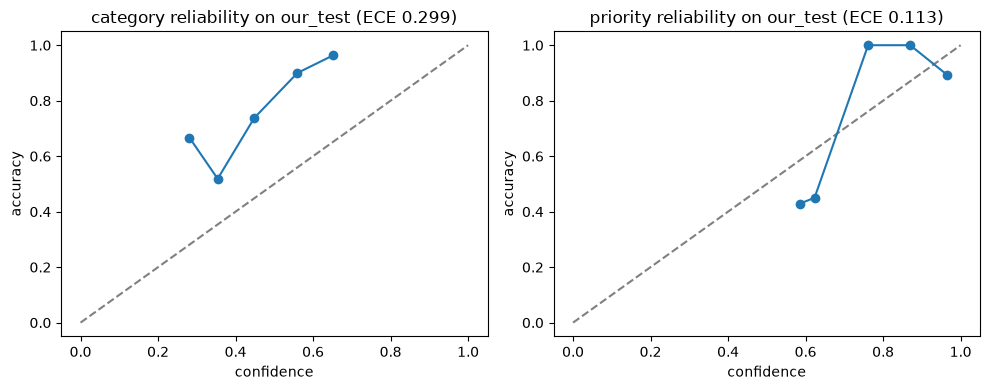

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cal in zip(axes, cov["calibration_our_test"], strict=True):
    bins = [b for b in cal["bins"] if b["count"]]
    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.plot([b["confidence"] for b in bins], [b["accuracy"] for b in bins], "o-")
    ax.set_title(f"{cal['target']} reliability on our_test (ECE {cal['ece']:.3f})")
    ax.set_xlabel("confidence")
    ax.set_ylabel("accuracy")
plt.tight_layout()
plt.show()

In [3]:
import math

import numpy as np

z = np.load(R / "conformal_scores.npz", allow_pickle=False)
for target in ("category", "priority"):
    s = z[f"scores_{target}"]
    n = len(s)
    q_row = np.sort(s)[min(math.ceil((n + 1) * 0.9), n) - 1]
    print(f"{target}: row-rule q = {q_row:.4f}; frozen q = {cov['config'][f'q_{target}']:.4f} "
          f"({cov['config']['calibration']} rule)")
try:  # independent cross-check of the row rule with mapie's quantile helper, when available
    from mapie.utils import compute_quantiles
    print("mapie:", compute_quantiles(z["scores_category"][:, None], np.array([0.9])).ravel())
except Exception as exc:  # the API moved between mapie releases; the numpy rule above is the reference
    print("mapie cross-check skipped:", type(exc).__name__)

category: row-rule q = 0.7791; frozen q = 0.7791 (group rule)
priority: row-rule q = 0.3949; frozen q = 0.5740 (group rule)


mapie cross-check skipped: ImportError
